<a href="https://www.kaggle.com/code/nicapotato/stray-kids-on-spotify?scriptVersionId=369140706" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Guided Listening Log — Stray Kids on Spotify
_One listener's play counts, album types, and how completely each track was heard_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [sayedgame3/spotify-skz-counts-album](https://www.kaggle.com/datasets/sayedgame3/spotify-skz-counts-album)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***

# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [Year and Album Type](#Year)** <br>
**5. [Completion and Tempo](#Completion)** <br>
**6. [What Lines Up with Play Count](#Model)** <br>
**7. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
Each row is one Stray Kids track in one listener's Spotify history, with a release year, an album type, a play count, a tempo, and how much of the track was heard. The file has 314 rows. Five of them are exact copies of earlier rows. After those copies are removed, 309 tracks remain and the play counts sum to 27,005. Streams here are this history's play counts. Years run from 2018 through 2026, and 2026 contains two tracks.

Blank BPM (8 rows), album type (5 rows), and average percent played (3 rows) stay blank. The question is when this listening concentrated, which album types carry the plays, and whether tempo or completion moves with the play count.

# **2. Setup and Data Peek:** <a id="Setup"></a>

In [1]:
# General
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
PALETTE = ["#30a2da", "#fc4f30", "#e5ae38", "#6d904f", "#8b8b8b"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


def park_legend(ax, title=""):
    ax.legend(
        title=title,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=False,
    )

**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the table; `matplotlib` / `seaborn` do the graphics; `scipy` ranks associations; `sklearn` fits one linear model on a hold-out split (`random_state=7`). `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series so sequential plots feel like one exploration. When a plot has a legend, `park_legend` places it to the right of the axes.

In [2]:
KAGGLE_SLUG = "sayedgame3/spotify-skz-counts-album"
CSV_NAME = "spotify_skz_counts_album.csv"


def resolve_file(basename: str, slug: str = KAGGLE_SLUG) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        for p in kaggle_root.rglob(basename):
            return p
    local_data = Path("data") / basename
    if local_data.exists():
        return local_data
    path = Path(kagglehub.dataset_download(slug))
    found = path / basename
    assert found.exists(), f"expected {basename} under {path}"
    return found


csv_path = resolve_file(CSV_NAME)
raw = pd.read_csv(csv_path)
print("CSV:", csv_path)
print("Dataframe Dimension:", raw.shape[0], "Rows,", raw.shape[1], "Columns")
assert raw.shape == (314, 12)
assert raw.duplicated().sum() == 5
df = raw.drop_duplicates().reset_index(drop=True)
assert len(df) == 309
assert int(df.number_of_streams.sum()) == 27005
print("Exact duplicate rows removed:", 5)
print("Tracks:", len(df), "| Play-count sum:", int(df.number_of_streams.sum()))
print("Null counts:")
print(df.isna().sum().to_string())
display(df.sample(5, random_state=7))
print(df.dtypes.to_string())

CSV: /kaggle/input/datasets/sayedgame3/spotify-skz-counts-album/spotify_skz_counts_album.csv
Dataframe Dimension: 314 Rows, 12 Columns
Exact duplicate rows removed: 5
Tracks: 309 | Play-count sum: 27005
Null counts:
release_year               0
album_type                 5
album_name                 0
track_name                 0
bpm                        8
number_of_streams          0
total_time_played          0
total_time_played_h        0
average_ms_played          0
average_ms_played_min      0
song_length_min            0
avg_percent_song_played    3


,release_year,album_type,album_name,track_name,bpm,number_of_streams,total_time_played,total_time_played_h,average_ms_played,average_ms_played_min,song_length_min,avg_percent_song_played
37,2019,Mini Album,Cle 1 - MIROH,Chronosaurus,100.0,22,4320551,1:12:01,196388.68,3:16,3:20,98.0
171,2023,Mini Album,ROCK-STAR,COMFLEX,110.0,43,7405906,2:03:26,172230.37,2:52,2:52,100.0
277,2025,Remix,CEREMONY (Maximum Power Remixes),CEREMONY (KARMA Version),138.0,40,6677536,1:51:18,166938.40,2:47,2:51,98.0
60,2020,Repackage,IN LIFE,B Me,150.0,19,3895831,1:04:56,205043.74,3:25,3:25,100.0
153,2022,Mini Album,MAXIDENT,CIRCUS (Korean Ver.),98.0,78,14968815,4:09:29,191907.88,3:12,3:14,99.0


release_year                 int64
album_type                  object
album_name                  object
track_name                  object
bpm                        float64
number_of_streams            int64
total_time_played            int64
total_time_played_h         object
average_ms_played          float64
average_ms_played_min       object
song_length_min             object
avg_percent_song_played    float64


**Code Explanation and Reasoning:** <br>
The five duplicate rows match earlier rows on every column. They are removed so a play count is added once. Blank BPM, album type, and completion stay blank and drop out only of the plot or model that needs that column.

# **3. Univariate Distributions:** <a id="Univariate"></a>

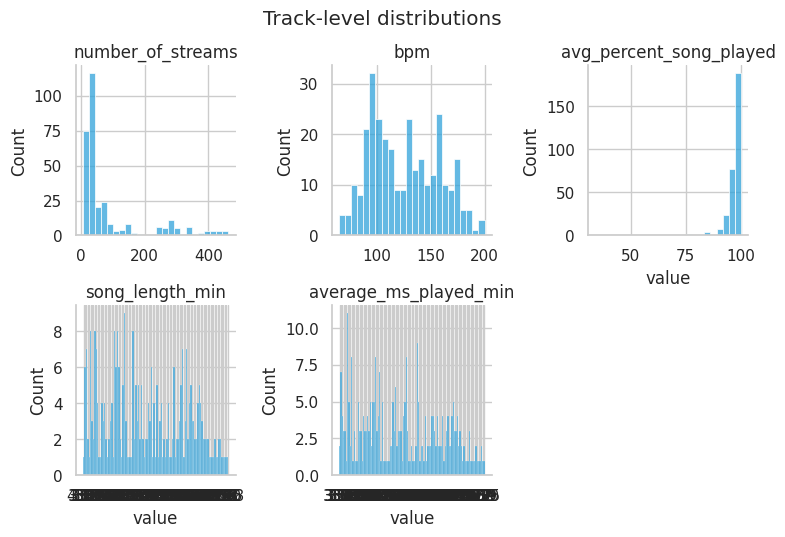

count    309.0
mean      87.4
std      110.1
min        5.0
50%       37.0
90%      281.2
max      463.0
Release years: 2018 - 2026
release_year
2018    28
2019    24
2020    37
2021    30
2022    51
2023    34
2024    53
2025    50
2026     2
Album type (blank left out):
album_type
Mini Album      96
Studio Album    65
Single          32
Compilation     30
Soundtrack      26
Mixtape         22
Remix           22
Repackage        8
Promo Single     3


In [3]:
value_cols = [
    "number_of_streams",
    "bpm",
    "avg_percent_song_played",
    "song_length_min",
    "average_ms_played_min",
]
long = df.melt(value_vars=value_cols, var_name="feature", value_name="value").dropna()
g = sns.FacetGrid(long, col="feature", col_wrap=3, sharex=False, sharey=False, height=2.6)
g.map_dataframe(sns.histplot, x="value", bins=24, color=PALETTE[0])
g.set_titles("{col_name}")
g.fig.suptitle("Track-level distributions", y=1.03)
plt.show()

print(df.number_of_streams.describe(percentiles=[0.5, 0.9]).round(1).to_string())
print("Release years:", int(df.release_year.min()), "-", int(df.release_year.max()))
print(df.release_year.value_counts().sort_index().to_string())
print("Album type (blank left out):")
print(df.album_type.value_counts(dropna=True).to_string())

**Interpretation:** <br>
Play counts are small and right-skewed: a median track in this history was played a few dozen times, and a handful of tracks were played a few hundred times. Completion piles up near a full play. Tempos sit in a band typical of this catalog. Album type is blank on 5 tracks; those five stay out of the type chart. 2026 contributes two tracks.

# **4. Year and Album Type:** <a id="Year"></a>

,count,sum,median
release_year,,,
2018,28,931,23
2019,24,590,20
2020,37,1470,32
2021,30,1430,24
2022,51,2043,30
2023,34,2057,38
2024,53,9700,241
2025,50,8738,94
2026,2,46,23


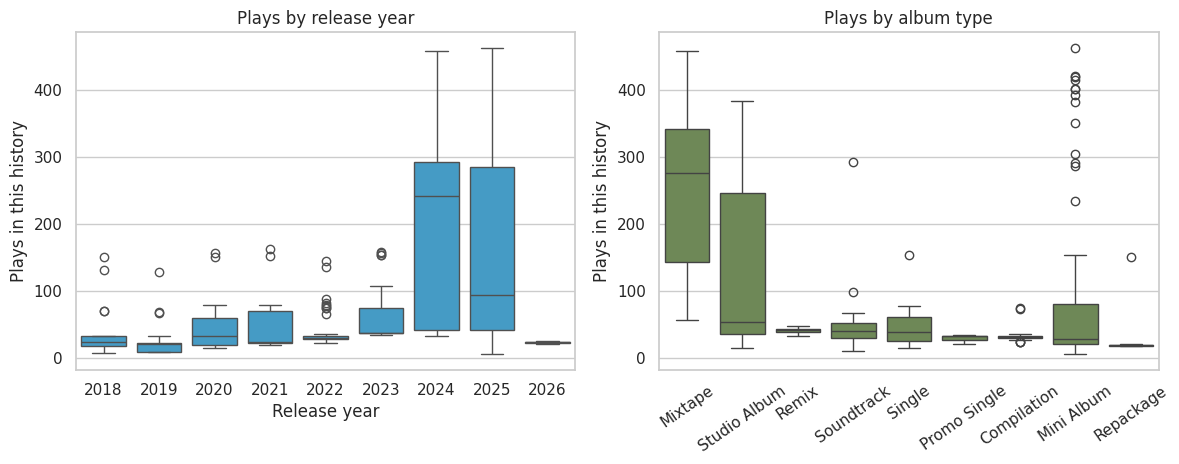

              count  median   sum
album_type                       
Mixtape          22   276.5  6026
Studio Album     65    53.0  7782
Remix            22    41.0   886
Soundtrack       26    40.0  1328
Single           32    38.5  1435
Promo Single      3    32.0    87
Compilation      30    31.0   991
Mini Album       96    28.0  7941
Repackage         8    19.0   281


,album_name,track_name,release_year,album_type,number_of_streams
258,Hollow,Hollow,2025,Mini Album,463
222,HOP,Walkin On Water,2024,Mixtape,458
272,Mixtape - DominATE,Truman (HAN and Felix),2025,Mixtape,454
268,Mixtape - DominATE,Burnin' Tires (Changbin and I.N),2025,Mixtape,435
270,Mixtape - DominATE,ESCAPE (Bang Chan and Hyunjin),2025,Mixtape,435
269,Mixtape - DominATE,CINEMA (Lee Know and Seungmin),2025,Mixtape,430
260,Hollow,Parade,2025,Mini Album,421
204,ATE,Chk Chk Boom,2024,Mini Album,419


Share of plays from 2024-2025 releases: 68.3%


In [4]:
by_year = df.groupby("release_year").number_of_streams.agg(["count", "sum", "median"])
display(by_year.style.format({"sum": "{:.0f}", "median": "{:.0f}"}).background_gradient(subset=["sum", "median"], cmap="Blues"))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.boxplot(data=df, x="release_year", y="number_of_streams", ax=axes[0], color=PALETTE[0])
axes[0].set_xlabel("Release year")
axes[0].set_ylabel("Plays in this history")
axes[0].set_title("Plays by release year")

typed = df.dropna(subset=["album_type"])
order = typed.groupby("album_type").number_of_streams.median().sort_values(ascending=False).index
sns.boxplot(data=typed, x="album_type", y="number_of_streams", order=order, ax=axes[1], color=PALETTE[3])
axes[1].set_xlabel("")
axes[1].set_ylabel("Plays in this history")
axes[1].set_title("Plays by album type")
axes[1].tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()

print(typed.groupby("album_type").number_of_streams.agg(["count", "median", "sum"]).sort_values("median", ascending=False).round(1).to_string())
top = df.nlargest(8, "number_of_streams")[["album_name", "track_name", "release_year", "album_type", "number_of_streams"]]
display(top)
share_recent = df.loc[df.release_year.isin([2024, 2025]), "number_of_streams"].sum() / df.number_of_streams.sum()
print("Share of plays from 2024-2025 releases:", f"{share_recent:.1%}")

**Interpretation:** <br>
2024 and 2025 releases hold 68.3% of the plays in this history. The 2024 median is 241 plays across 53 tracks; earlier years sit near a median of a few dozen. Mixtape is the high album type, with median 276.5 plays across 22 tracks, against a studio median of 53. The leading titles in this history — Hollow, Walkin On Water, Truman, and the tracks printed beside them — are 2024–2025 plays, which is when this log got heavier.

# **5. Completion and Tempo:** <a id="Completion"></a>

Spearman plays vs avg percent played: -0.375 (n=306, p=1.165e-11)
Spearman plays vs bpm: 0.151 (n=301, p=8.816e-03)
Spearman plays vs song length (min): -0.250 (n=309, p=8.946e-06)


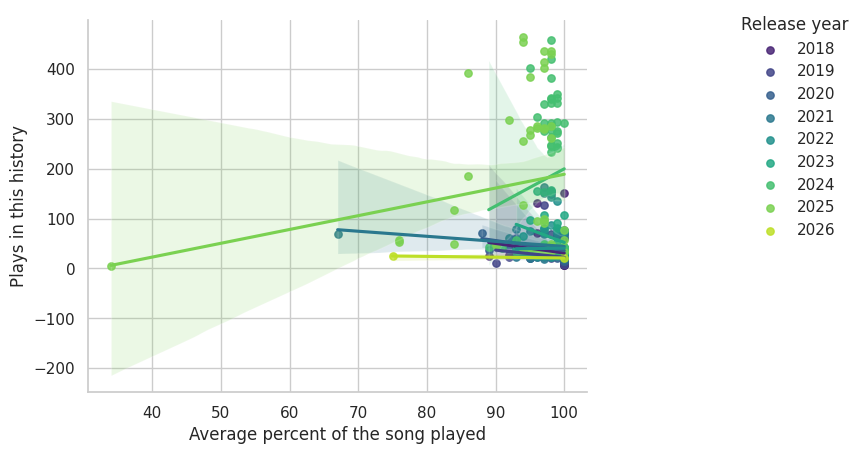

In [5]:
complete = df.dropna(subset=["avg_percent_song_played"])
tempo = df.dropna(subset=["bpm"])
for label, frame, col in [
    ("avg percent played", complete, "avg_percent_song_played"),
    ("bpm", tempo, "bpm"),
    ("song length (min)", df, "song_length_min"),
]:
    rho, p = stats.spearmanr(frame.number_of_streams, frame[col])
    print(f"Spearman plays vs {label}: {rho:.3f} (n={len(frame)}, p={p:.3e})")

g = sns.lmplot(
    data=complete,
    x="avg_percent_song_played",
    y="number_of_streams",
    hue="release_year",
    palette="viridis",
    height=4.6,
    aspect=1.35,
    scatter_kws={"s": 28, "alpha": 0.85},
    legend=True,
)
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Release year", frameon=False)
g.set_axis_labels("Average percent of the song played", "Plays in this history")
plt.show()

**Interpretation:** <br>
Plays and completion move in opposite directions (Spearman −0.375 on the rows with a completion value). Tracks this listener played many times were, on average, finished a little less completely. Tempo is a weak positive association (Spearman 0.151 on the rows with a BPM). Length leans the other way (Spearman −0.250): longer tracks in this history have fewer plays. The color on the scatter is release year: the high play counts sit on the recent years, across a wide range of completion.

# **6. What Lines Up with Play Count:** <a id="Model"></a>

In [6]:
model_df = df.dropna(subset=["album_type"]).copy()
assert len(model_df) == 304
y = model_df.number_of_streams
X = model_df[["release_year", "album_type"]]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=7)
year_only = LinearRegression().fit(Xtr[["release_year"]], ytr)
print("Hold-out R2, plays ~ year:", round(r2_score(yte, year_only.predict(Xte[["release_year"]])), 3))
print("Plays per release year:", round(year_only.coef_[0], 2))

pipe = Pipeline([
    ("pre", ColumnTransformer([
        ("num", "passthrough", ["release_year"]),
        ("cat", OneHotEncoder(drop="first"), ["album_type"]),
    ])),
    ("lr", LinearRegression()),
])
pipe.fit(Xtr, ytr)
print("Hold-out R2, plays ~ year + album type:", round(r2_score(yte, pipe.predict(Xte)), 3))
print("Reference album type (dropped level):", sorted(model_df.album_type.unique())[0])
names = pipe.named_steps["pre"].get_feature_names_out()
for name, coef in zip(names, pipe.named_steps["lr"].coef_):
    print(f"{name:40s} {coef:8.2f}")

Hold-out R2, plays ~ year: 0.227
Plays per release year: 22.96
Hold-out R2, plays ~ year + album type: 0.574
Reference album type (dropped level): Compilation
num__release_year                           28.64
cat__album_type_Mini Album                  89.93
cat__album_type_Mixtape                    156.60
cat__album_type_Promo Single               -80.40
cat__album_type_Remix                      -63.79
cat__album_type_Repackage                   64.61
cat__album_type_Single                      16.72
cat__album_type_Soundtrack                 -16.21
cat__album_type_Studio Album                66.98


**Interpretation:** <br>
Year alone has hold-out R² 0.227, about 23 more plays per release year in this history. Adding album type raises the hold-out R² to 0.574. The dropped album-type level is Compilation, so the printed type coefficients are differences from Compilation. Five tracks with a blank album type stay out of this fit. The year slope is the 2024–2025 jump showing up as a line; the type terms are the mixtape and unit-track difference that year does not absorb.

# **7. What It Means — Working Synthesis:** <a id="Synthesis"></a> <br>
This is one listener's Stray Kids history: 309 tracks after five exact duplicate rows are removed, and 27,005 plays. 2024 and 2025 releases account for 68.3% of those plays. A mixtape track's median is 276.5 plays; a studio track's median is 53. Year plus album type reaches a hold-out R² of 0.574, against 0.227 for year alone.

Tracks with more plays were finished a little less completely (Spearman −0.375), and longer tracks have fewer plays (Spearman −0.250). Tempo's association is weaker (Spearman 0.151). Blank BPM, album type, and completion stay blank. 2026 is two tracks.

**Open follow-ups:** <br>
- A later export of the same account would show whether 2024–2025 stays the heavy period or was the stretch when this history was collected.
- Global Spotify totals for these tracks are a different table from this account's play counts.